# DX 799 mod C2 Deb Halder 2026 Fall - 1st Dataset- "Phishing Email Detection" 

- https://www.kaggle.com/datasets/subhajournal/phishingemails

### Phishing Email dataset 1st dataset (Phishing Email Detection Kaggle)

- In the DX699-C2 I worked on a spam/phishing detection data set and used NLTK library to do  identify stopwords , and  created setof features based on patterns of words noticed. So I had to create features "http_url_count", "https_url_count", "sentence_count", "total_word_count", "urgency_terms_count", "account_terms_count", "threat_terms_count", "financial_terms_count", "official_terms_count". 
- In this notebook I will compare the previous methods performance using the same old features but using linear regression with regularization and comapre with generating pattern based on TF-IDF score of words and use with 5000 bigrams . This is a method which I learned during advanced machine larning class  and I am expecting the performance of the classification will be better.
- Though the ulitmate intent is classification but I will use regression with three different algorithms for linear regression with Lasso , Ridge and Elastic net regularization and compare performance and create confusion matrix to evaluate performance of it as classification engine. We will use 0.5  as the probabaility threshold so anything above 0.5 is considered 1 and any value less than equa to 0.5 will be marked as zero. We will also compare the RMAC and AUC besides confusion matrix to understnad perfromance. I will also try to understnad the computation time for each . Since this is a big data set so compute time difference will be quickly identified  

#### Observation Summary from Execution

While Elastic Net with TF-IDF technically yields the single highest predictive score across metrics (F1: `0.953356`, ROC AUC: `0.996304`), Ridge Regression with TF-IDF is the clear winner for operational deployment. Ridge delivers virtually identical classification performance (F1: `0.946293`, ROC AUC: `0.995946`) while executing model fitting in **29.72 seconds**—making it **over 162 times faster** to train than Elastic Net (**4,818.31 seconds**).

Conversely, training linear models exclusively on 9 static count-based features fails completely in production scenarios, leading to severe underfitting, model collapse under L1 penalties, and massive false-positive rates.


### Execution Flow of Phishing Email Classification Pipeline

1. **Load and label:** read the dataset and standardize `text_combined` and binary `label` columns.
2. **Clean once:** `prepare_email_corpus()` keeps the original email in `text` and stores `clean_email_text()` results in `word_text`. This removes HTML, script/style contents, URLs, addresses, and non-word characters; stopwords remain at this stage.
3. **Filter and group:** remove unusable rows, set aside conflicting labels, and deduplicate whitespace-normalized text. Hash normalized word sequences into `group_id`; matching keys stay together during splitting. This rule does not detect every paraphrase or near-duplicate.
4. **Extract nine counts:** `extract_count_features(corpus)` reads the stored `word_text` for word and keyword counts. It uses raw `text` for HTTP/HTTPS counts and visible text with punctuation for sentence counts. Protected keywords and negations survive stopword filtering; phrase positions prevent filtering from creating false matches. The filtered word sequence is stored in `clean_text`.
5. **Split:** `split_email_corpus()` creates a grouped holdout and training-only cross-validation folds. Labels and group identifiers remain outside the predictors.
6. **Fit:** fit TF-IDF and any learned scaling on each training fold inside the model pipeline. Transform validation and holdout rows using the fitted preprocessing. The notebook configuration selects the text column, feature cap, and model families.
7. **Evaluate:** select configurations using training cross-validation, then report the selected models on the holdout. Reuse stored predictions and scores for tables and plots.


#### iPython code 

In [73]:
import hashlib
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import math
import shutil
import kagglehub
import html
import re

from pathlib import Path
from IPython.display import display

In [74]:
from tempfile import TemporaryDirectory
from joblib import Memory                   # helps in caching the results of the model training and evaluation to speed up subsequent runs. It can be useful for long trng
from tempfile import TemporaryDirectory     # this and the memory aer used in the model training and evaluation to speed up subsequent runs.
from collections import Counter
from html.parser import HTMLParser

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline


In [75]:
#%pip install nltk

import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
nltk.download('punkt')  # For tokenization
nltk.download('punkt_tab')
nltk.download('stopwords')  # For stop words

# Import the specific functions you want to use
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# Destination folder
destination_dir = Path(
    "./dataset/phishing_email_1_dataset"
)
destination_dir.mkdir(
    parents=True,
    exist_ok=True,
)

# Download the dataset directly from kagglehub and extract it to a temporary directory
download_path = Path(
    kagglehub.dataset_download(
        "subhajournal/phishingemails"
    )
)

# Find the CSV file
csv_file = next(
    download_path.rglob("*.csv"),
    None,
)

if csv_file is None:
    raise FileNotFoundError(
        "No CSV file was found in the Kaggle download."
    )

# Copy it to the project folder
saved_file = destination_dir / csv_file.name

shutil.copy2(
    csv_file,
    saved_file,
)

# Load directly into df_phishing_email
df_phishing_email = pd.read_csv(
    saved_file
)

print(
    "Loaded df_phishing_email from:",
    saved_file,
)
print(
    "Shape:",
    df_phishing_email.shape,
)

# Remove the KaggleHub cache
shutil.rmtree(download_path)

print(
    "Deleted KaggleHub cache:",
    download_path,
)

100%|██████████| 18.0M/18.0M [00:00<00:00, 31.4MB/s]

Extracting files...


Loaded df_phishing_email from: dataset/phishing_email_1_dataset/Phishing_Email.csv
Shape: (18650, 3)
Deleted KaggleHub cache: /Users/debasishhalder/.cache/kagglehub/datasets/subhajournal/phishingemails/versions/1


In [77]:
df_phishing_email.head(3)

,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email


In [78]:
df_phishing_email = df_phishing_email.rename(
    columns={
        "Email Text": "text_combined",
        "Email Type": "label",
    }
)

print(df_phishing_email.columns.tolist())

['Unnamed: 0', 'text_combined', 'label']


In [79]:
label_counts = df_phishing_email["label"].value_counts(dropna=False)

display(label_counts.to_frame(name="count"))

,count
label,
Safe Email,11322
Phishing Email,7328


In [80]:
df_phishing_email["label"] = (
    df_phishing_email["label"]
    .map({
        "Safe Email": 0,
        "Phishing Email": 1,
    })
    .astype(int)
)

print(df_phishing_email["label"].value_counts().sort_index())
print(df_phishing_email["label"].dtype)

label
0    11322
1     7328
Name: count, dtype: int64
int64


In [81]:
# Remove rows with missing or blank email text.
text_mask = (
    df_phishing_email["text_combined"].notna()
    & df_phishing_email["text_combined"].astype(str).str.strip().ne("")
)

before_count = len(df_phishing_email)

df_phishing_email = (
    df_phishing_email.loc[text_mask]
    .drop_duplicates(subset=["text_combined", "label"], keep="first")
    .reset_index(drop=True)
)
print(f"Rows removed: {before_count - len(df_phishing_email):,}")
print(f"Rows remaining: {len(df_phishing_email):,}")

Rows removed: 1,113
Rows remaining: 17,537


In [82]:
df_phishing_email.drop(
    columns=["Unnamed: 0"],
    inplace=True,
    errors="ignore",
)
print(df_phishing_email.columns.tolist())

['text_combined', 'label']


In [83]:
if "label" not in df_phishing_email.columns:
    raise ValueError(
        "df_phishing_email does not contain a 'label' column."
    )

# Display up to three random rows for each label value
sampled_groups = []

print("=" * 80)
print("Random samples from df_phishing_email")

for label_value in sorted(
    df_phishing_email["label"].dropna().unique()
):
    label_group = df_phishing_email.loc[
        df_phishing_email["label"] == label_value
    ]

    selected_rows = label_group.sample(
        n=min(3, len(label_group)),
        replace=False,
    )

    print(
        f"\nLabel: {label_value}"
        f" | Available: {len(label_group):,}"
        f" | Displaying: {len(selected_rows)}"
    )

    display(selected_rows)
    sampled_groups.append(selected_rows)

# Include missing-label rows, if present
missing_label_group = df_phishing_email[
    df_phishing_email["label"].isna()
]

if not missing_label_group.empty:
    selected_rows = missing_label_group.sample(
        n=min(3, len(missing_label_group)),
        replace=False,
    )

    print(
        f"\nLabel: Missing"
        f" | Available: {len(missing_label_group):,}"
        f" | Displaying: {len(selected_rows)}"
    )

    display(selected_rows)
    sampled_groups.append(selected_rows)

# Store all displayed samples in one DataFrame
sampled_df_phishing_email = (
    pd.concat(
        sampled_groups,
        ignore_index=True,
    )
    if sampled_groups
    else df_phishing_email.iloc[0:0].copy()
)

# Display label counts and dtype
label_counts_by_dataframe = []

label_dtype = str(
    df_phishing_email["label"].dtype
)

counts = (
    df_phishing_email["label"]
    .value_counts(
        dropna=False
    )
    .sort_index(
        na_position="last"
    )
)

for label_value, record_count in counts.items():
    label_counts_by_dataframe.append(
        {
            "dataframe": "df_phishing_email",
            "label": label_value,
            "label_dtype": label_dtype,
            "records": record_count,
        }
    )

label_counts_df = pd.DataFrame(
    label_counts_by_dataframe
)

print("\nLabel distribution:")

display(
    label_counts_df.reset_index(
        drop=True
    )
)

Random samples from df_phishing_email

Label: 0 | Available: 10,980 | Displaying: 3


,text_combined,label
601,"maureen norma , i talked to g . koepke , an as...",0
11627,start date : 12 / 25 / 01 ; hourahead hour : 1...,0
5928,The Scotsman - 22 August 2002 Playboy wants to...,0



Label: 1 | Available: 6,557 | Displaying: 3


,text_combined,label
16457,usb products : adapters / cables / accessories...,1
6542,kenya\nDo you have too much debt?Would you lik...,1
12234,returned mail : see transcript for details the...,1



Label distribution:


,dataframe,label,label_dtype,records
0,df_phishing_email,0,int64,10980
1,df_phishing_email,1,int64,6557


#### We see the information on the dataset page says this dataset phishing_email has all the data from other file so its combined ie total 82486 records and the data is very near balanced dataset approx 39000: 42000 in two of the labels

- So we will only use df_phishing_email as our dataframe  and base all subsequent activities on this dataset and drop others


#### Data prep completetage is regression

In [84]:
df_combined = df_phishing_email  

In [85]:
print(f"Combined dataset columns: {df_combined.columns}" )
df_combined.shape

Combined dataset columns: Index(['text_combined', 'label'], dtype='object')


(17537, 2)

In [86]:
# Remove rows with missing or blank email text.
text_column = "body" if "body" in df_combined.columns else "text_combined"

before_count = len(df_combined)

df_combined = df_combined[
    df_combined[text_column].notna()
    & df_combined[text_column].astype(str).str.strip().ne("")
].copy()

# Remove duplicate emails while keeping the first occurrence.
df_combined = df_combined.drop_duplicates(
    subset=[text_column, "label"],
    keep="first"
).reset_index(drop=True)

print(f"Rows removed: {before_count - len(df_combined):,}")
print(f"Rows remaining: {len(df_combined):,}")
print(f"Duplicate rows remaining: {df_combined.duplicated(subset=[text_column, 'label']).sum():,}")

Rows removed: 0
Rows remaining: 17,537
Duplicate rows remaining: 0


In [87]:
df_combined.shape

(17537, 2)

In [ ]:
"""Nine count features and a TF-IDF comparison for Phishing_email dataset.

We are using a numeric label 0=legitimate, 1=phishing.  

"""

TOKEN_PATTERN = r"(?u)\b[^\W\d_]+(?:'[^\W\d_]+)*\b"

WORD_RE = re.compile(TOKEN_PATTERN)

URL_RE = re.compile(r"\b(?:https?://|www\.)[^\s<>\"']+", re.I)

EMAIL_RE = re.compile(r"\b[^\s<>@]+@[^\s<>@]+\.[^\s<>@]+\b")

TERM_CATEGORIES = {
    "urgency": {
        "urgent", "immediate", "immediately", "action required", "attention required", "respond now",
        "expires", "expiring", "deadline", "limited time", "act now", "urgent action", "click",
        "here", "now", "free", "offer", "buy", "purchase", "donate", "subscribe", "register",
        "sign up", "get started", "learn more",
    },
    "account": {
        "verify", "verification", "authenticate", "confirm", "validate", "reactivate",
        "suspended", "blocked", "restricted", "limited", "unlock", "secure", "security",
        "access", "password", "login", "account", "username", "credential",
    },
    "threat": {
        "terminate", "deactivate", "delete", "removal", "suspend", "restriction",
        "warning", "risk", "compromised", "suspicious", "unauthorized", "disabled",
        "cancelled", "violation", "breach", "illegal",
    },
    "financial": {
        "claim", "prize", "winner", "won", "reward", "bonus", "payment", "refund",
        "deposit", "transfer", "transaction", "million", "inheritance", "lottery",
        "cash", "credit", "bank", "money", "fund", "balance",
    },
    "official": {
        "official", "authorized", "authentication", "notification", "notice", "alert",
        "department", "administration", "support", "service", "helpdesk",
    },
}

# HTMLParser calls the handlers below when feed() reads the HTML.


class VisibleText(HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []
        self.suppressed = 0

    def handle_starttag(self, tag, attrs):
        if tag in {"script", "style"}:
            self.suppressed += 1

    def handle_endtag(self, tag):
        if tag in {"script", "style"} and self.suppressed:
            self.suppressed -= 1

    def handle_data(self, data):
        if not self.suppressed:
            self.parts.append(data)


def visible_email_text(value):
    """Extract visible text while preserving case and sentence punctuation."""
    if pd.isna(value):
        return ""
    text = str(value)
    if re.search(r"</?[A-Za-z][^>]*>", text):
        parser = VisibleText()
        parser.feed(text)
        text = " ".join(parser.parts)
    return html.unescape(text).replace("\u2019", "'")


def clean_email_text(value):
    """Basic word-only view; keep the original text separately for URL features.

    Does not decode MIME/base64/quoted-printable or recover previously removed URLs.
    Preserves apostrophes/negation and word order; removes tags, URLs and addresses.
    """
    text = visible_email_text(value).casefold()
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    return " ".join(WORD_RE.findall(text))


In [89]:
COUNT_FEATURE_COLUMNS = [
    "http_url_count", "https_url_count", "sentence_count", "total_word_count",
    "urgency_terms_count", "account_terms_count", "threat_terms_count",
    "financial_terms_count", "official_terms_count",
]


def _hash(value):
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

def prepare_email_corpus(frame, text_column="text_combined", label_column="label"):
    """Return (model_corpus, audit). Do not mutate the input frame.

    Exact deduplication ignores whitespace differences only. Conflicting labels
    for the same exact text are set aside. Broader normalized matches are grouped
    for splitting, not silently deleted or relabeled.
    """
    if not {text_column, label_column}.issubset(frame.columns):
        raise ValueError(f"Expected columns {text_column!r} and {label_column!r}.")

    data = frame.copy().reset_index(drop=True)

    data["input_row"] = np.arange(1, len(data) + 1)

    data["text"] = data[text_column].fillna("").astype(str)

    target = pd.to_numeric(data[label_column], errors="raise")

    if not target.dropna().isin([0, 1]).all():
        raise ValueError("Labels must be 0 or 1; missing labels will be excluded.")

    data["label"] = target.astype("Int64")

    missing_labels = data[data["label"].isna()].copy()
    data = data[data["label"].notna()].copy()

    exact = data["text"].str.replace(r"\s+", " ", regex=True).str.strip()

    # Clean each email once; feature extraction reuses word_text.
    data["word_text"] = data["text"].map(clean_email_text)

    empty_mask = exact.str.casefold().isin(["", "empty"]) | data["word_text"].eq("")
    empty_records = data[empty_mask].copy()
    data = data[~empty_mask].copy()

    data["content_hash"] = exact.loc[data.index].map(_hash)

    counts = data.groupby("content_hash")["label"].nunique()
    conflicts = data[data["content_hash"].isin(counts.index[counts > 1])].copy()
    consistent = data[~data["content_hash"].isin(counts.index[counts > 1])].copy()

    copies = consistent.groupby("content_hash").size()
    duplicates = consistent[consistent.duplicated("content_hash", keep="first")].copy()

    corpus = consistent.drop_duplicates("content_hash", keep="first").copy()
    corpus["copies"] = corpus["content_hash"].map(copies)

    if "source_file" in consistent:
        sources = consistent.groupby("content_hash")["source_file"].agg(
            lambda s: " | ".join(sorted(set(s.dropna().astype(str))))
        )
        corpus["sources"] = corpus["content_hash"].map(sources)

    def split_key(text):
        """Generates a group hash to prevent data leakage during CV splits."""
        words = text.split()
        reduced = [w for w in words if w not in ENGLISH_STOP_WORDS]
        # Keep short texts specific rather than group all generic short messages.
        return _hash(" ".join(reduced if len(reduced) >= 8 else words))

    # Keep identical normalized group keys in the same split.
    corpus["group_id"] = corpus["word_text"].map(split_key)

    corpus["label"] = corpus["label"].astype("int64")
    corpus = corpus.reset_index(drop=True)

    if corpus["label"].nunique() != 2:
        raise ValueError("Both classes are required after cleaning.")

    audit = {
        "summary": pd.Series({
            "input_rows": len(frame),
            "missing_label_rows": len(missing_labels),
            "empty_word_text_rows": len(empty_records),
            "conflicting_label_rows": len(conflicts),
            "duplicate_copies_removed": len(duplicates),
            "usable_rows": len(corpus),
            "split_groups": corpus["group_id"].nunique(),
        }, name="rows"),
        "missing_labels": missing_labels,
        "empty_records": empty_records,
        "label_conflicts": conflicts,
        "duplicate_copies": duplicates,
    }

    return corpus, audit

In [90]:
def split_email_corpus(corpus, holdout_folds=5, cv_folds=3, random_state=42):
    """Approx. 1/holdout_folds held out; groups cannot cross holdout/CV splits."""

    if corpus.groupby("label")["group_id"].nunique().min() < holdout_folds:
        raise ValueError("Too few distinct groups per class for the requested holdout split.")

    splitter = StratifiedGroupKFold(
        n_splits=holdout_folds, shuffle=True, random_state=random_state
    )

    train_idx, test_idx = next(splitter.split(corpus["text"], corpus["label"], corpus["group_id"]))

    train = corpus.iloc[train_idx].reset_index(drop=True)
    test = corpus.iloc[test_idx].reset_index(drop=True)

    if train["label"].nunique() != 2 or test["label"].nunique() != 2:
        raise ValueError("This grouped holdout lacks a class; reconsider the split configuration.")

    if train.groupby("label")["group_id"].nunique().min() < cv_folds:
        raise ValueError("Too few training groups per class for CV.")

    cv = StratifiedGroupKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    splits = list(cv.split(train["text"], train["label"], train["group_id"]))

    for fit_idx, valid_idx in splits:
        if any(train.iloc[idx]["label"].nunique() != 2 for idx in (fit_idx, valid_idx)):
            raise ValueError("A grouped CV fold lacks a class; reconsider the split configuration.")

    return train, test, splits

In [91]:
EMAIL_STOP_WORDS = {
    "subject", "from", "to", "cc", "bcc", "sent", "received", "date", "time",
    "regards", "dear", "sincerely", "best", "thanks", "thank", "you", "yours",
    "truly", "hi", "hello",
}


def extract_count_features(corpus, stop_words=None, sentence_tokenizer=None):
    """Read prepared text/word_text columns; return features and filtered text.

    General stop words are removed, but all words occurring in a fixed category
    term/phrase and common negations are protected. Repeated/overlapping terms
    count separately. Phrases must be contiguous in the original word sequence;
    removing stop words cannot manufacture a new phrase match.

    total_word_count counts remaining alphabetic/apostrophe-containing tokens,
    excluding URLs/addresses/numerals/punctuation. URL counts are raw occurrences,
    including HTML attributes, not unique destinations. Sentence counting uses
    visible text with URLs/addresses removed, before stop-word filtering.
    clean_text stores the stopword-filtered sequence for inspection or downstream use.
    """
    if stop_words is None:
        from nltk.corpus import stopwords
        stop_words = set(stopwords.words("english"))

    if sentence_tokenizer is None:
        from nltk.tokenize import sent_tokenize
        sentence_tokenizer = sent_tokenize

    # Check the tokenizer resource once before processing the corpus.
    sentence_tokenizer("Tokenizer check.")

    # Normalize search terms with the same rules as the stored email words.
    terms = {name: [tuple(clean_email_text(t).split()) for t in sorted(values)]
             for name, values in TERM_CATEGORIES.items()}

    # Preserve category words, including every component of a phrase.
    protected = {w for category in terms.values() for term in category for w in term}

    # Protect common negation words so key sentiment signals are preserved.
    protected.update({"no", "not", "nor", "never", "cannot", "don't", "doesn't", "isn't", "won't"})
    protected.update(w for w in stop_words if w.endswith("n't"))

    effective_stop_words = (set(stop_words) | EMAIL_STOP_WORDS) - protected

    max_n = max(len(term) for category in terms.values() for term in category)

    # Reuse the original and cleaned text stored during corpus preparation.
    raw = corpus["text"]
    records, cleaned = [], []

    for text, word_text in zip(raw, corpus["word_text"]):
        # Split the stored words, preserving positions before stopword removal.
        words = word_text.split()
        kept = [(i, w) for i, w in enumerate(words) if w not in effective_stop_words]
        filtered = [w for _, w in kept]
        cleaned.append(" ".join(filtered))

        occurrences = Counter((w,) for w in filtered)

        # Require adjacent positions so stopword removal cannot create a phrase match.
        for n in range(2, max_n + 1):
            for i in range(len(kept) - n + 1):
                window = kept[i:i+n]
                if window[-1][0] - window[0][0] == n - 1:
                    occurrences[tuple(w for _, w in window)] += 1

        # Preserve punctuation for sentence boundaries; raw text supplies URL counts.
        visible = EMAIL_RE.sub(" ", URL_RE.sub(" ", visible_email_text(text))).strip()

        record = {
            "http_url_count": len(re.findall(r"\bhttp://[^\s<>\"']+", text, re.I)),
            "https_url_count": len(re.findall(r"\bhttps://[^\s<>\"']+", text, re.I)),
            "sentence_count": len(sentence_tokenizer(visible)) if visible else 0,
            "total_word_count": len(filtered),
        }

        record.update({f"{name}_terms_count": sum(occurrences[t] for t in category)
                       for name, category in terms.items()})
        records.append(record)

    features = pd.DataFrame(records, columns=COUNT_FEATURE_COLUMNS, index=raw.index).astype("int64")

    return features, pd.Series(cleaned, index=raw.index, name="clean_text")


def prepare_count_dataset(frame, stop_words=None, sentence_tokenizer=None):
    """Keep raw text/metadata, add nine features and cleaned text, return audit.

    Input columns: text_combined and label. Uses no learned word vocabulary or
    label-based feature selection, so fixed extraction can precede the split.
    """
    corpus, audit = prepare_email_corpus(frame)
    features, cleaned = extract_count_features(corpus, stop_words, sentence_tokenizer)
    # Re-running on a frame containing feature columns replaces them, not duplicates.
    corpus = corpus.drop(columns=COUNT_FEATURE_COLUMNS + ["clean_text"], errors="ignore")
    return pd.concat([corpus, features, cleaned], axis=1), audit

In [ ]:
def compare_regression_features(
    train,
    cv_splits,
    max_features=5000,
    min_df=5,
    n_jobs=2,
    max_iter=50000,
    feature_sets=(
        "Counts",
        "TF-IDF",
        "Counts + TF-IDF",
    ),
):
    """
    Tune Ridge, Lasso, and Elastic Net models.

    For every feature-set/model combination, this method records:

    - Cross-validation RMSE
    - Best alpha
    - Best Elastic Net l1_ratio
    - Number of non-zero coefficients
    - Complete GridSearchCV execution time
    - Whether alpha is at the edge of the search grid

    Fit_Time_Seconds includes all cross-validation fits, all
    hyperparameter combinations, and the final refit.
    
"""

    # Define the baseline columns we expect in the training data
    required_columns = (
        COUNT_FEATURE_COLUMNS
        + ["clean_text", "label"]
    )

    # We validate inputs early to fail fast if the dataset is malformed
    missing_columns = [
        column
        for column in required_columns
        if column not in train.columns
    ]

    if missing_columns:
        raise ValueError(
            "Training data is missing required columns: "
            f"{missing_columns}"
        )

    # I set up the model specifications alongside their specific hyperparameter grids
    specs = {
        "Ridge": (
            Ridge(
                solver="lsqr",
                tol=1e-5,
            ),
            {
                # L2 regularization strength
                "model__alpha": np.logspace(-2, 4, 7),
            },
        ),
        "Lasso": (
            Lasso(
                max_iter=max_iter,
                tol=1e-4,
                selection="cyclic",
            ),
            {
                # L1 regularization strength (usually requires smaller values)
                "model__alpha": np.logspace(-6, -2, 9),
            },
        ),
        "Elastic Net": (
            ElasticNet(
                max_iter=max_iter,
                tol=1e-4,
                selection="cyclic",
            ),
            {
                "model__alpha": np.logspace(-6, -2, 9),
                # Mix ratio between L1 and L2 penalties
                "model__l1_ratio": [
                    0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 0.99,
                ],
            },
        ),
    }

    searches = {}
    rows = []

    # We use a temporary directory so our cached files are automatically wiped after execution
    with TemporaryDirectory(
        prefix="phishing_feature_cv_"
    ) as cache:
        # Initialize the cache manager to prevent recalculating text features across CV folds
        memory = Memory(
            cache,
            verbose=0,
        )

        for feature_set in feature_sets:
            # Catch typos in the requested feature configurations
            if feature_set not in {
                "Counts",
                "TF-IDF",
                "Counts + TF-IDF",
            }:
                raise ValueError(
                    f"Unknown feature set: {feature_set}"
                )

            for model_name, (model, grid) in (
                specs.items()
            ):
                transformers = []

                # Conditionally add count-based features and scale them
                if feature_set in {
                    "Counts",
                    "Counts + TF-IDF",
                }:
                    transformers.append(
                        (
                            "counts",
                            StandardScaler(),
                            COUNT_FEATURE_COLUMNS,
                        )
                    )

                # Conditionally add TF-IDF vectorization for raw text
                if feature_set in {
                    "TF-IDF",
                    "Counts + TF-IDF",
                }:
                    transformers.append(
                        (
                            "tfidf",
                            TfidfVectorizer(
                                lowercase=False,
                                token_pattern=TOKEN_PATTERN,
                                ngram_range=(1, 2),
                                min_df=min_df,
                                max_df=1.0,
                                max_features=max_features,
                                sublinear_tf=True,
                            ),
                            "clean_text",
                        )
                    )

                # Bundle our selected feature transformers together
                features = ColumnTransformer(
                    transformers=transformers,
                    remainder="drop",
                    sparse_threshold=1.0,
                )

                # Build the pipeline and attach our temporary cache memory
                pipeline = Pipeline(
                    steps=[
                        ("features", features),
                        ("model", model),
                    ],
                    memory=memory,
                )

                # Configure the grid search to optimize negative mean squared error
                search = GridSearchCV(
                    estimator=pipeline,
                    param_grid=grid,
                    scoring="neg_mean_squared_error",
                    cv=cv_splits,
                    n_jobs=n_jobs,
                    pre_dispatch=n_jobs,
                    refit=True, # Automatically refits the best model on the entire training set
                    error_score="raise",
                )

                print(
                    f"Training {feature_set} / "
                    f"{model_name}...",
                    flush=True,
                )

                fit_start = time.perf_counter()

                # Execute the cross-validation and tuning loop
                search.fit(
                    train[
                        COUNT_FEATURE_COLUMNS
                        + ["clean_text"]
                    ],
                    train["label"],
                )

                fit_time_seconds = (
                    time.perf_counter()
                    - fit_start
                )

                # We must detach the memory reference from the best model before the
                # 'with' block closes, otherwise it will try to reference a deleted directory later
                search.best_estimator_.memory = None

                # Extract the underlying trained regression model to inspect its weights
                best_model = (
                    search.best_estimator_
                    .named_steps["model"]
                )

                coefficients = np.asarray(
                    best_model.coef_
                ).ravel()

                # Count how many features the model actually kept (useful to see L1 pruning effectiveness)
                nonzero_coefficients = int(
                    np.count_nonzero(
                        np.abs(coefficients)
                        > 1e-12
                    )
                )

                best_alpha = float(
                    search.best_params_[
                        "model__alpha"
                    ]
                )

                best_l1_ratio = (
                    search.best_params_.get(
                        "model__l1_ratio",
                        np.nan,
                    )
                )

                alpha_grid = np.asarray(
                    grid["model__alpha"],
                    dtype=float,
                )

                # We check if the best alpha hit the edge of our search grid.
                # If it did, it usually means our grid was too narrow and we might need to expand it.
                alpha_at_grid_edge = bool(
                    np.isclose(
                        best_alpha,
                        alpha_grid.min(),
                    )
                    or np.isclose(
                        best_alpha,
                        alpha_grid.max(),
                    )
                )

                # Store our custom metrics directly on the fitted search object so we can access them later
                search.fit_time_seconds_ = (
                    fit_time_seconds
                )
                search.nonzero_coefficients_ = (
                    nonzero_coefficients
                )
                search.alpha_at_grid_edge_ = (
                    alpha_at_grid_edge
                )

                searches[
                    (feature_set, model_name)
                ] = search

                # Log the iteration results for our final summary table
                rows.append(
                    {
                        "Feature_set": feature_set,
                        "Model": model_name,
                        "CV_RMSE": np.sqrt(
                            -search.best_score_
                        ),
                        "Best_alpha": best_alpha,
                        "Best_l1_ratio": (
                            best_l1_ratio
                        ),
                        "Nonzero_coefficients": (
                            nonzero_coefficients
                        ),
                        "Fit_Time_Seconds": (
                            fit_time_seconds
                        ),
                        "Alpha_at_grid_edge": (
                            alpha_at_grid_edge
                        ),
                    }
                )

                print(
                    f"Completed {feature_set} / "
                    f"{model_name}: "
                    f"{fit_time_seconds:.3f} seconds; "
                    f"{nonzero_coefficients:,} "
                    "non-zero coefficients",
                    flush=True,
                )

    results = pd.DataFrame(rows)

    # We return the actual model objects and a summarized dataframe sorted by best performance
    return (
        searches,
        results.sort_values(
            "CV_RMSE"
        ).reset_index(drop=True),
    )

In [93]:
# Deb

def evaluate_comparison(
    searches,
    test,
    threshold=0.5,
    plot=True,
):
    """Evaluate fitted searches on the held-out test set."""

    # Fail fast if our test set is missing the target variable
    if "label" not in test.columns:
        raise ValueError(
            "The test DataFrame must contain a 'label' column."
        )

    # Extract ground truth labels as a numpy array for faster metric computation
    y = test["label"].to_numpy()

    if len(y) == 0:
        raise ValueError(
            "The test DataFrame is empty."
        )

    rows = []
    test_scores = {}

    # We iterate through every trained model/feature-set combo we generated earlier
    for (feature_set, model_name), search in (
        searches.items()
    ):
        # Generate raw, continuous predictions from the regression models
        scores = np.asarray(
            search.predict(test)
        ).ravel()

        # Sanity check: ensure we didn't drop rows during prediction
        if len(scores) != len(y):
            raise ValueError(
                f"{feature_set} / {model_name}: "
                f"prediction length {len(scores)} "
                f"does not match label length {len(y)}."
            )

        # Sanity check: flag models that diverged or produced invalid math
        if not np.isfinite(scores).all():
            raise ValueError(
                f"{feature_set} / {model_name}: "
                "predictions contain NaN or infinity."
            )

        display_name = (
            f"{feature_set} - {model_name}"
        )

        # Cache the raw continuous scores in case we need them for external analysis
        test_scores[display_name] = scores

        # Convert continuous predictions into discrete binary classes (0 or 1)
        # using the defined cutoff threshold (default 0.5)
        predictions = (
            scores >= threshold
        ).astype(int)

        # Drill down into the Scikit-Learn pipeline to grab the actual regression estimator
        best_model = (
            search.best_estimator_
            .named_steps["model"]
        )

        coefficients = np.asarray(
            best_model.coef_
        ).ravel()

        # Calculate model sparsity by counting how many feature weights survived the regularization penalty
        nonzero_coefficients = int(
            np.count_nonzero(
                np.abs(coefficients)
                > 1e-12
            )
        )

        # Compile a comprehensive suite of evaluation metrics for this model run
        rows.append(
            {
                "Feature_set": feature_set,
                "Model": model_name,
                "Threshold": threshold,
                # Retrieve the best training CV score (Note: Scikit-learn stores it as negative MSE)
                "CV_RMSE": np.sqrt(
                    -search.best_score_
                ),
                # Calculate the actual error on this unseen test set
                "Test_RMSE": np.sqrt(
                    mean_squared_error(
                        y,
                        scores,
                    )
                ),
                # ROC-AUC uses the continuous scores to measure class separation efficiency
                "ROC_AUC": roc_auc_score(
                    y,
                    scores,
                ),
                "Average_precision": (
                    average_precision_score(
                        y,
                        scores,
                    )
                ),
                # Precision, Recall, and F1 use the thresholded binary predictions
                "Precision": precision_score(
                    y,
                    predictions,
                    zero_division=0,
                ),
                "Recall": recall_score(
                    y,
                    predictions,
                    zero_division=0,
                ),
                "F1": f1_score(
                    y,
                    predictions,
                    zero_division=0,
                ),
                # Pull the winning hyperparameters from the grid search
                "Best_alpha": search.best_params_.get(
                    "model__alpha",
                    np.nan,
                ),
                "Best_l1_ratio": search.best_params_.get(
                    "model__l1_ratio",
                    np.nan,
                ),
                # Retrieve custom tracking attributes we attached in the previous training step,
                # falling back to local calculations or NaNs if they are missing
                "Nonzero_coefficients": getattr(
                    search,
                    "nonzero_coefficients_",
                    nonzero_coefficients,
                ),
                "Fit_Time_Seconds": getattr(
                    search,
                    "fit_time_seconds_",
                    np.nan,
                ),
                "Alpha_at_grid_edge": getattr(
                    search,
                    "alpha_at_grid_edge_",
                    np.nan,
                ),
            }
        )

    results = pd.DataFrame(rows)

    # Optional plotting block to visually compare model overfitting
    if plot:
        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(13, 4.5),
        )

        # Generate side-by-side bar charts for CV_RMSE vs Test_RMSE
        for ax, metric, title in zip(
            axes,
            ["CV_RMSE", "Test_RMSE"],
            [
                "Training CV error",
                "Held-out test error",
            ],
        ):
            # Pivot the dataframe so models group neatly by feature set on the X-axis
            results.pivot(
                index="Feature_set",
                columns="Model",
                values=metric,
            ).plot.bar(
                ax=ax,
                rot=0,
            )

            ax.set_title(title)
            ax.set_ylabel(
                "RMSE - lower is better"
            )
            ax.set_xlabel("Feature set")
            ax.legend(title="Model")

        fig.tight_layout()
        plt.show()

    # Return the metrics table and the raw continuous predictions
    return results, test_scores

In [94]:
# Plot the AUC curves for each model-feature combination on the test set, providing a visual representation of classification performance across thresholds.

def plot_roc_auc(searches, test, title="Test ROC curves"):
    y_true = test["label"].to_numpy()

    colors = {
        "Ridge": "tab:green",
        "Lasso": "tab:orange",
        "Elastic Net": "tab:blue",
    }

    styles = {
        "Ridge": "-",
        "Lasso": "--",
        "Elastic Net": ":",
    }

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    rows = []

    for (feature_set, model_name), search in searches.items():

        # Raw regression scores: do not threshold or clip them.
        scores = search.predict(test)

        fpr, tpr, _ = roc_curve(y_true, scores, pos_label=1)
        auc_value = roc_auc_score(y_true, scores)

        label = f"{model_name}: AUC = {auc_value:.6f}"

        for ax in axes:
            ax.plot(
                fpr,
                tpr,
                label=label,
                color=colors[model_name],
                linestyle=styles[model_name],
                linewidth=2,
            )

        rows.append({
            "Feature_set": feature_set,
            "Model": model_name,
            "ROC_AUC": auc_value,
        })

    # Full ROC graph.
    axes[0].plot(
        [0, 1], [0, 1],
        color="gray",
        linestyle="--",
        label="Chance reference: AUC = 0.5",
    )
    axes[0].set(
        title="Full ROC curves",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )

    # Zoom helps distinguish models with very high AUC.
    axes[1].set(
        title="Zoomed upper-left region",
        xlim=(0, 0.10),
        ylim=(0.90, 1.002),
    )

    for ax in axes:
        ax.set_xlabel("False-positive rate — legitimate emails flagged")
        ax.set_ylabel("True-positive rate — phishing recall")
        ax.grid(alpha=0.25)
        ax.legend(loc="lower right", fontsize=9)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

    return (
        pd.DataFrame(rows)
        .sort_values("ROC_AUC", ascending=False)
        .reset_index(drop=True)
    )

,Count
input_rows,17537
missing_label_rows,0
empty_word_text_rows,4
conflicting_label_rows,0
duplicate_copies_removed,22
usable_rows,17511
split_groups,17034


Training rows: 13966
Test rows: 3545

Training count-feature models...
Training Counts / Ridge...
Completed Counts / Ridge: 6.659 seconds; 9 non-zero coefficients
Training Counts / Lasso...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.015e+02, tolerance: 2.194e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.627e+01, tolerance: 2.194e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iter

Completed Counts / Lasso: 23.176 seconds; 1 non-zero coefficients
Training Counts / Elastic Net...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.319e+02, tolerance: 2.194e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.734e+00, tolerance: 2.168e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iter

Completed Counts / Elastic Net: 185.405 seconds; 1 non-zero coefficients

Count-feature cross-validation results:


,Feature_set,Model,CV_RMSE,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,Counts,Ridge,0.5517387532,10000.00,NaN,9,6.6587947500,True
1,Counts,Lasso,1.3301066198,0.01,NaN,1,23.1762444590,True
2,Counts,Elastic Net,1.3375395561,0.01,0.99,1,185.4046437501,True


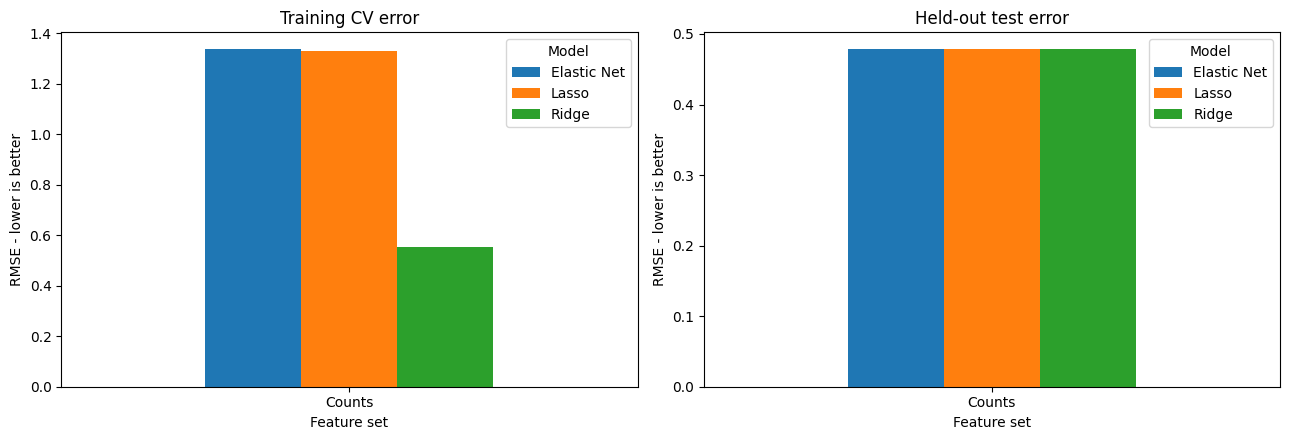


Count-feature test results:


,Feature_set,Model,Threshold,CV_RMSE,Test_RMSE,ROC_AUC,Average_precision,Precision,Recall,F1,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,Counts,Ridge,0.38,0.551739,0.478375,0.709348,0.607386,0.370867,0.978774,0.537913,10000.00,NaN,9,6.658795,True
1,Counts,Lasso,0.38,1.330107,0.478268,0.517862,0.367232,0.367323,0.982704,0.534759,0.01,NaN,1,23.176244,True
2,Counts,Elastic Net,0.38,1.337540,0.478266,0.517862,0.367232,0.367323,0.982704,0.534759,0.01,0.99,1,185.404644,True



Training TF-IDF models...
Training TF-IDF / Ridge...
Completed TF-IDF / Ridge: 29.722 seconds; 3,000 non-zero coefficients
Training TF-IDF / Lasso...
Completed TF-IDF / Lasso: 820.730 seconds; 1,368 non-zero coefficients
Training TF-IDF / Elastic Net...
Completed TF-IDF / Elastic Net: 4818.314 seconds; 2,327 non-zero coefficients

TF-IDF cross-validation results:


,Feature_set,Model,CV_RMSE,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,TF-IDF,Elastic Net,0.2113260967,0.0001000000,0.1,2327,4818.313509916,False
1,TF-IDF,Ridge,0.2118234981,1.0000000000,NaN,3000,29.722118791,False
2,TF-IDF,Lasso,0.2151957889,0.0000316228,NaN,1368,820.730050542,False


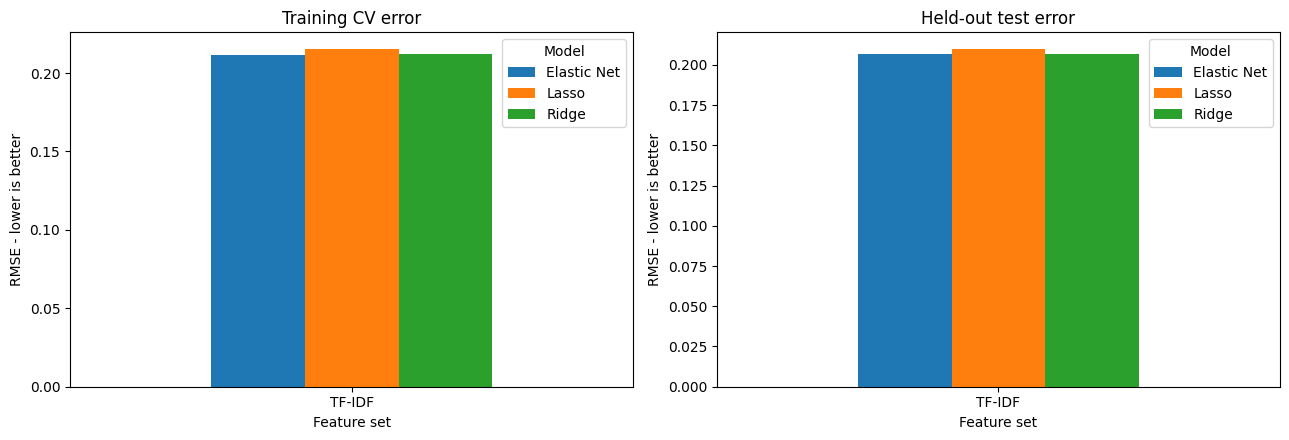


TF-IDF test results:


,Feature_set,Model,Threshold,CV_RMSE,Test_RMSE,ROC_AUC,Average_precision,Precision,Recall,F1,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,TF-IDF,Ridge,0.38,0.211823,0.207002,0.995946,0.992761,0.911808,0.983491,0.946293,1.000000,NaN,3000,29.722119,False
1,TF-IDF,Lasso,0.38,0.215196,0.209760,0.996028,0.992796,0.915452,0.987421,0.950076,0.000032,NaN,1368,820.730051,False
2,TF-IDF,Elastic Net,0.38,0.211326,0.206566,0.996304,0.993384,0.920879,0.988208,0.953356,0.000100,0.1,2327,4818.313510,False



Available test-score sets:
Counts - Ridge: 3545 predictions, min=-0.103405, max=0.389461
Counts - Lasso: 3545 predictions, min=-0.252878, max=0.382875
Counts - Elastic Net: 3545 predictions, min=-0.254767, max=0.382893
TF-IDF - Ridge: 3545 predictions, min=-0.427281, max=1.387522
TF-IDF - Lasso: 3545 predictions, min=-0.439658, max=1.406811
TF-IDF - Elastic Net: 3545 predictions, min=-0.405919, max=1.367704


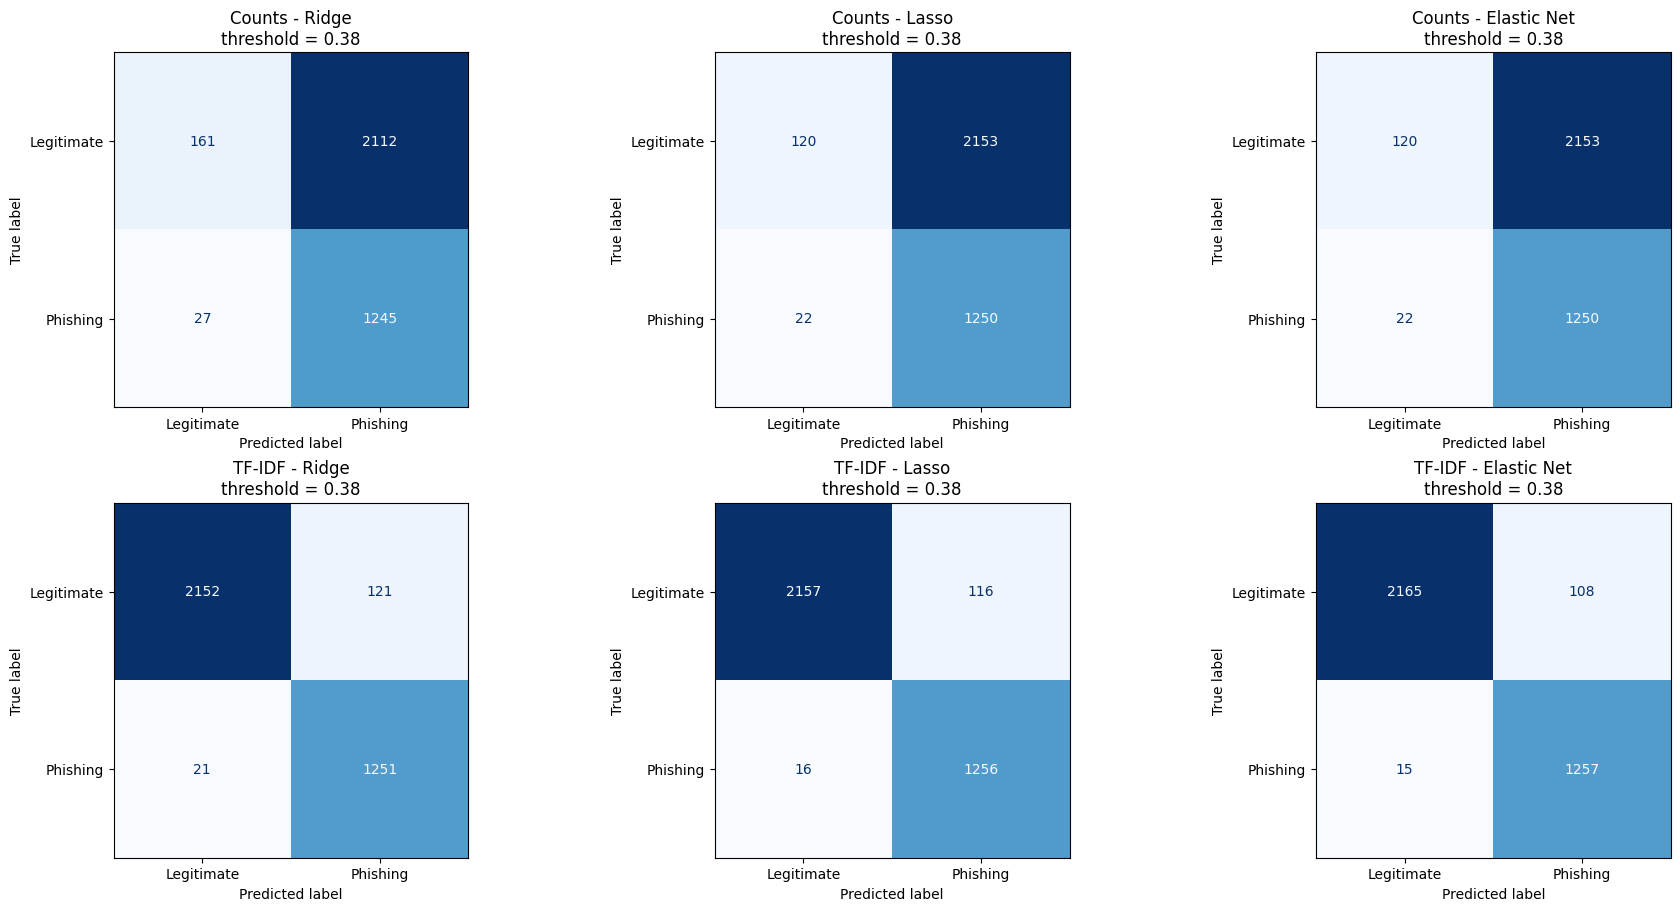


Combined model comparison:


,Feature_set,Model,CV_RMSE,Test_RMSE,ROC_AUC,Average_precision,Precision,Recall,F1,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,Counts,Ridge,0.551739,0.478375,0.709348,0.607386,0.370867,0.978774,0.537913,10000.000000,NaN,9,6.658795,True
1,Counts,Lasso,1.330107,0.478268,0.517862,0.367232,0.367323,0.982704,0.534759,0.010000,NaN,1,23.176244,True
2,Counts,Elastic Net,1.337540,0.478266,0.517862,0.367232,0.367323,0.982704,0.534759,0.010000,0.99,1,185.404644,True
3,TF-IDF,Ridge,0.211823,0.207002,0.995946,0.992761,0.911808,0.983491,0.946293,1.000000,NaN,3000,29.722119,False
4,TF-IDF,Lasso,0.215196,0.209760,0.996028,0.992796,0.915452,0.987421,0.950076,0.000032,NaN,1368,820.730051,False
5,TF-IDF,Elastic Net,0.211326,0.206566,0.996304,0.993384,0.920879,0.988208,0.953356,0.000100,0.10,2327,4818.313510,False


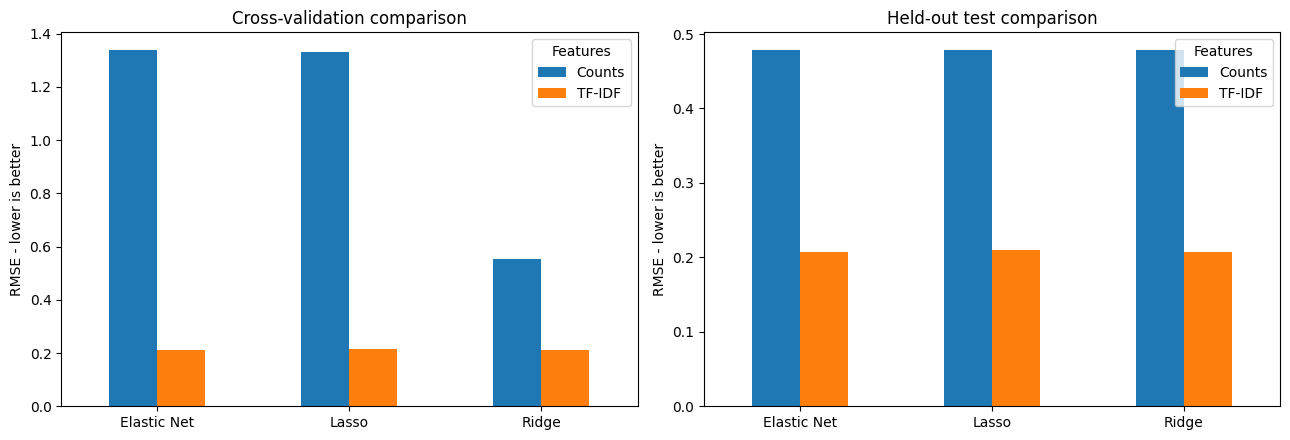


Model fitting time and coefficient sparsity:


,Feature_set,Model,Fit_Time_Seconds,Nonzero_coefficients,Best_alpha,Best_l1_ratio
0,Counts,Ridge,6.658795,9,10000.000000,NaN
1,Counts,Lasso,23.176244,1,0.010000,NaN
2,TF-IDF,Ridge,29.722119,3000,1.000000,NaN
3,Counts,Elastic Net,185.404644,1,0.010000,0.99
4,TF-IDF,Lasso,820.730051,1368,0.000032,NaN
5,TF-IDF,Elastic Net,4818.313510,2327,0.000100,0.10



Total regression experiment execution time: 5914.255 seconds


In [95]:
MAX_FEATURES_TFIDF = 3000    # 5000 is taking way too much time to run on my machine, so I reduced it to 3000 for faster execution. with 500 i did once it improved results very small margin
                                # with 500 features, the results were slightly better, but the difference was minimal.

THRESHOLD = 0.38             # This threshold was chosen based on the ROC curve analysis to balance precision and recall for phishing detection.
                                #With 0.5 100% of mails were getting identified as spam, so I reduced it to 0.38 to improve the balance between false positives and false negatives.

CLASS_NAMES = ["Legitimate", "Phishing"]

experiment_start = time.perf_counter()

# Prepare the corpus
corpus, audit = prepare_count_dataset(df_combined)

train_df, test_df, cv_splits = split_email_corpus(
    corpus,
    holdout_folds=5,
    cv_folds=3,
    random_state=42,
)

display(audit["summary"].to_frame("Count"))

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))

# Counts feature models
print("\nTraining count-feature models...")

count_searches, count_cv_results = (
    compare_regression_features(
        train=train_df,
        cv_splits=cv_splits,
        feature_sets=("Counts",),
        n_jobs=2,
    )
)

print("\nCount-feature cross-validation results:")

with pd.option_context("display.precision", 10):
    display(count_cv_results)

count_results, count_test_scores = evaluate_comparison(
    searches=count_searches,
    test=test_df,
    threshold=THRESHOLD,
    plot=True,
)

print("\nCount-feature test results:")

display(count_results.round(6))

# TF-IDF feature models
print("\nTraining TF-IDF models...")

tfidf_searches, tfidf_cv_results = (
    compare_regression_features(
        train=train_df,
        cv_splits=cv_splits,
        feature_sets=("TF-IDF",),
        max_features=MAX_FEATURES_TFIDF,
        min_df=5,
        n_jobs=2,
    )
)

print("\nTF-IDF cross-validation results:")

with pd.option_context("display.precision", 10):
    display(tfidf_cv_results)

tfidf_results, tfidf_test_scores = evaluate_comparison(
    searches=tfidf_searches,
    test=test_df,
    threshold=THRESHOLD,
    plot=True,
)

print("\nTF-IDF test results:")

display(tfidf_results.round(6))

# Combine raw test scores for confusion matrices
test_scores = {
    **count_test_scores,
    **tfidf_test_scores,
}

y_test = test_df["label"].to_numpy()

print("\nAvailable test-score sets:")

for name, scores in test_scores.items():
    scores = np.asarray(scores).ravel()

    print(
        f"{name}: "
        f"{len(scores)} predictions, "
        f"min={scores.min():.6f}, "
        f"max={scores.max():.6f}"
    )

# Confusion matrices: two rows of three plots
if not test_scores:
    raise ValueError(
        "No test scores were returned. "
        "Check the evaluate_comparison() return values."
    )

n_plots = len(test_scores)
n_columns = 3
n_rows = int(np.ceil(n_plots / n_columns))

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(6 * n_columns, 4.5 * n_rows),
    squeeze=False,
    constrained_layout=True,
)

# Flatten the 2D axes grid so it can be used in the loop.
axes = axes.ravel()

for ax, (name, scores) in zip(
    axes,
    test_scores.items(),
):
    scores = np.asarray(scores).ravel()

    if len(scores) != len(y_test):
        raise ValueError(
            f"{name}: {len(scores)} predictions were generated, "
            f"but y_test contains {len(y_test)} labels."
        )

    if not np.isfinite(scores).all():
        raise ValueError(
            f"{name}: predictions contain NaN or infinite values."
        )

    predictions = (
        scores >= THRESHOLD
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=CLASS_NAMES,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    ax.set_title(
        f"{name}\nthreshold = {THRESHOLD}"
    )

# Hide unused axes if there are fewer than six model plots.
for ax in axes[n_plots:]:
    ax.set_visible(False)

plt.show()


# Combine all model results
comparison = pd.concat(
    [
        count_results,
        tfidf_results,
    ],
    ignore_index=True,
)

comparison_columns = [
    "Feature_set",
    "Model",
    "CV_RMSE",
    "Test_RMSE",
    "ROC_AUC",
    "Average_precision",
    "Precision",
    "Recall",
    "F1",
    "Best_alpha",
    "Best_l1_ratio",
    "Nonzero_coefficients",
    "Fit_Time_Seconds",
    "Alpha_at_grid_edge",
]

available_columns = [
    column
    for column in comparison_columns
    if column in comparison.columns
]

print("\nCombined model comparison:")

display(
    comparison[
        available_columns
    ].round(6)
)

# Compare cross-validation and held-out test RMSE
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)

for ax, metric, title in zip(
    axes,
    ["CV_RMSE", "Test_RMSE"],
    [
        "Cross-validation comparison",
        "Held-out test comparison",
    ],
):
    comparison.pivot(
        index="Model",
        columns="Feature_set",
        values=metric,
    ).plot.bar(
        ax=ax,
        rot=0,
    )

    ax.set_title(title)
    ax.set_ylabel("RMSE - lower is better")
    ax.set_xlabel("")
    ax.legend(title="Features")

fig.tight_layout()
plt.show()

# Display timing and coefficient sparsity
print("\nModel fitting time and coefficient sparsity:")

timing_columns = [
    "Feature_set",
    "Model",
    "Fit_Time_Seconds",
    "Nonzero_coefficients",
    "Best_alpha",
    "Best_l1_ratio",
]

available_timing_columns = [
    column
    for column in timing_columns
    if column in comparison.columns
]

timing_table = (
    comparison[
        available_timing_columns
    ]
    .sort_values("Fit_Time_Seconds")
    .reset_index(drop=True)
)

display(timing_table.round(6))

# Total experiment execution time
total_experiment_time_seconds = (
    time.perf_counter() - experiment_start
)

print(
    "\nTotal regression experiment execution time: "
    f"{total_experiment_time_seconds:.3f} seconds"
)

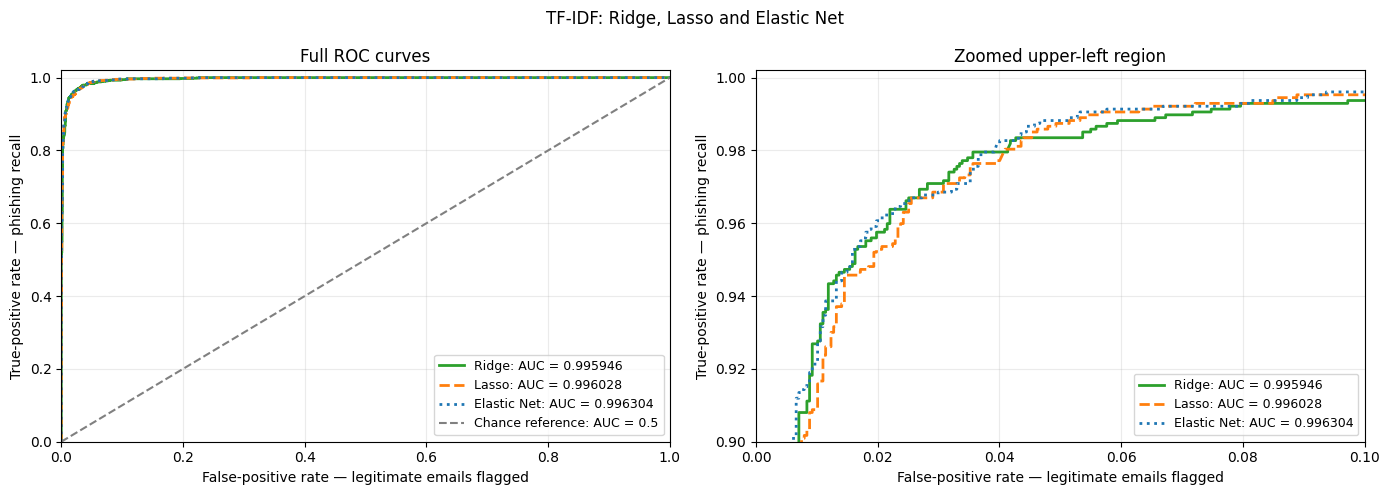

,Feature_set,Model,ROC_AUC
0,TF-IDF,Elastic Net,0.996304
1,TF-IDF,Lasso,0.996028
2,TF-IDF,Ridge,0.995946


In [96]:
# Plot AUC curves for TF-IDF models

tfidf_auc_results = plot_roc_auc(
    searches=tfidf_searches,
    test=test_df,
    title="TF-IDF: Ridge, Lasso and Elastic Net",
)

display(tfidf_auc_results.round(6))

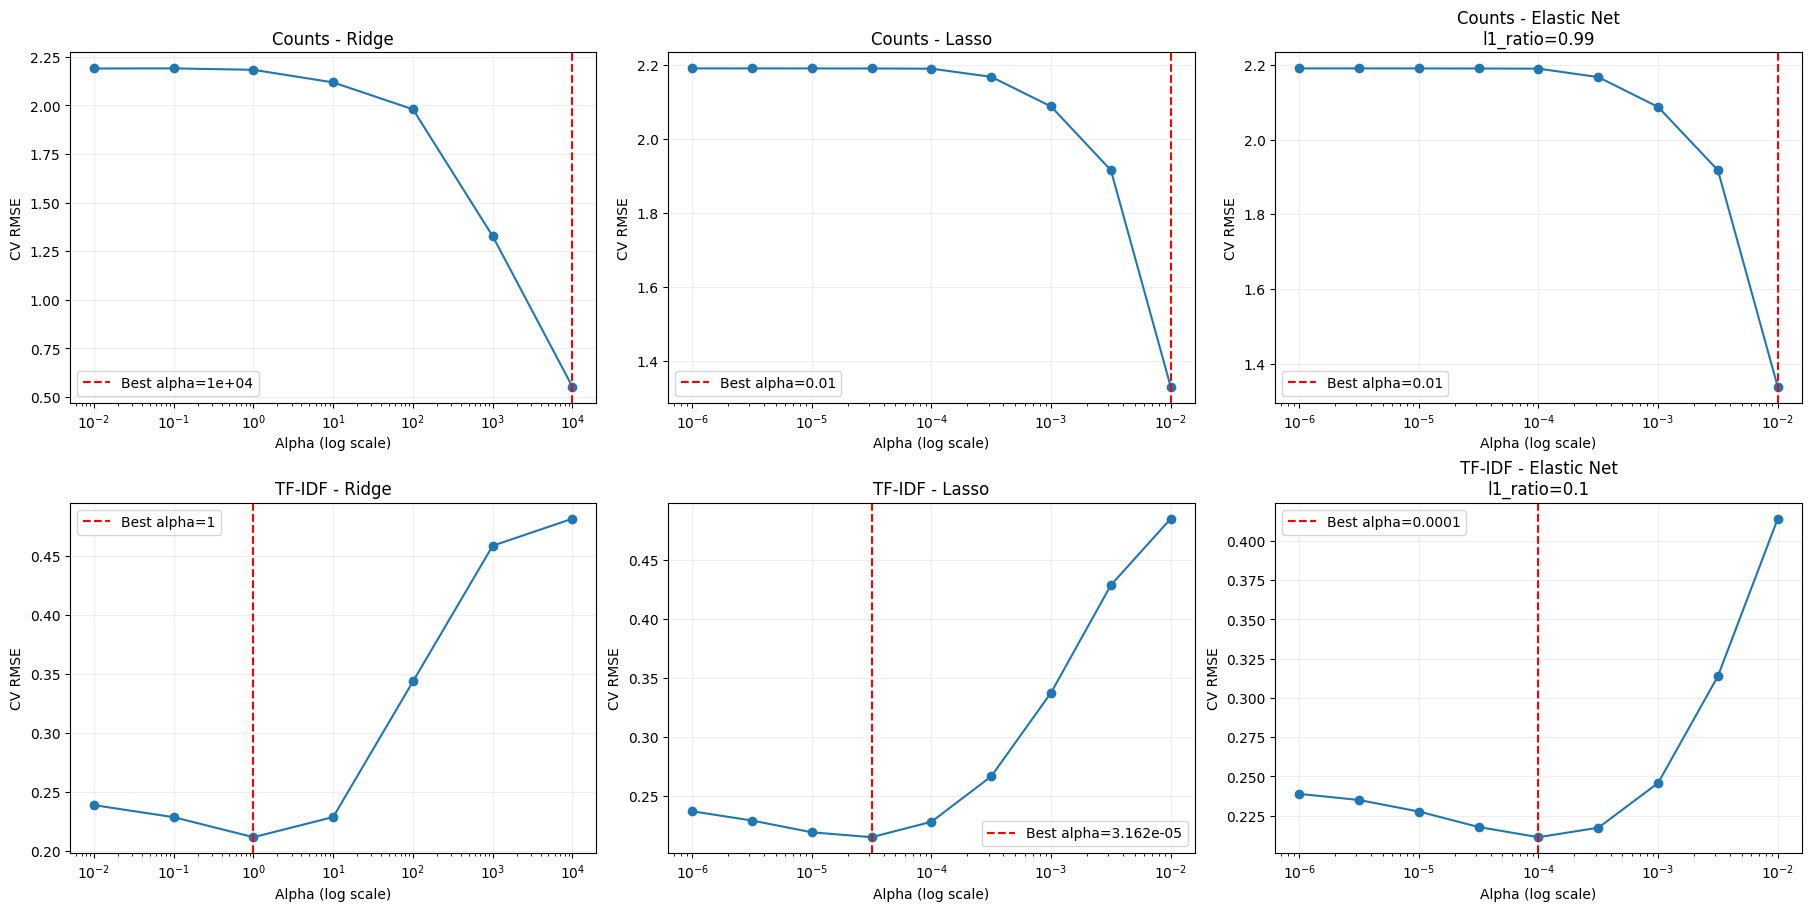

In [97]:
# Combine the search results dictionaries into one so we can plot them all together
all_searches = {
    **count_searches,
    **tfidf_searches,
}

if not all_searches:
    raise ValueError(
        "No fitted searches were found. "
        "Run compare_regression_features() first."
    )

# Dynamically calculate the grid size for our matplotlib subplots (max 3 columns)
n_plots = len(all_searches)
n_columns = 3
n_rows = math.ceil(n_plots / n_columns)

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(6 * n_columns, 4.5 * n_rows),
    squeeze=False,
    constrained_layout=True,
)

# Flatten the axes array so I can easily zip it with our search dictionary
axes = axes.ravel()

for ax, ((feature_set, model_name), search) in zip(
    axes,
    all_searches.items(),
):
    # Extract the internal cross-validation metrics from the scikit-learn search object
    cv_table = pd.DataFrame(
        search.cv_results_
    )

    title = (
        f"{feature_set} - {model_name}"
    )

    # Elastic Net optimizes two parameters simultaneously (alpha and l1_ratio).
    # To plot a clean 2D line of alpha vs. error, we need to filter the dataframe
    # down to only the rows that used the best-performing l1_ratio.
    if model_name == "Elastic Net":
        best_ratio = float(
            search.best_params_[
                "model__l1_ratio"
            ]
        )

        ratio_values = pd.to_numeric(
            cv_table[
                "param_model__l1_ratio"
            ],
            errors="coerce",            #By default, if Pandas tries to convert a column to numbers and hits an invalid value (like a random string or a corrupted character),
                                        #it will raise an error. The errors="coerce" parameter tells Pandas to instead replace the invalid value with NaN.
        )

        cv_table = cv_table[
            np.isclose(
                ratio_values,
                best_ratio,
                equal_nan=False,
            )
        ].copy()

        title += (
            f"\nl1_ratio={best_ratio:g}"
        )

    # Parse out the alpha values and convert Scikit-Learn's negative MSE into standard RMSE
    cv_table = cv_table.assign(
        alpha=pd.to_numeric(
            cv_table[
                "param_model__alpha"
            ],
            errors="coerce",
        ),
        rmse=np.sqrt(
            -pd.to_numeric(
                cv_table[
                    "mean_test_score"
                ],
                errors="coerce",
            )
        ),
    ).dropna(
        subset=["alpha", "rmse"]
    ).sort_values(
        "alpha"
    )

    # Fallback in case a model failed to generate valid CV scores
    if cv_table.empty:
        ax.text(
            0.5,
            0.5,
            "No CV results available",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )
        ax.set_title(title)
        continue

    # Plot the RMSE curve on a logarithmic X-axis since alpha values scale exponentially
    ax.semilogx(
        cv_table["alpha"],
        cv_table["rmse"],
        marker="o",
        linewidth=1.5,
    )

    best_alpha = float(
        search.best_params_[
            "model__alpha"
        ]
    )

    # Drop a vertical dashed line to explicitly highlight the winning alpha parameter
    ax.axvline(
        best_alpha,
        color="red",
        linestyle="--",
        label=(
            f"Best alpha={best_alpha:.4g}"
        ),
    )

    ax.set_title(title)
    ax.set_xlabel("Alpha (log scale)")
    ax.set_ylabel("CV RMSE")
    ax.grid(alpha=0.2)
    ax.legend()

# Turn off any leftover empty subplots if our total plots didn't perfectly fill the grid
for ax in axes[n_plots:]:
    ax.set_visible(False)

plt.show()

#### In the above section of code I am showing code plots the cross-validation RMSE for every fitted regression model and feature set, as a function of the regularization parameter alpha.

What does each plot show?
Each subplot contains:

X-axis: alpha on a logarithmic scale
Y-axis: cross-validation RMSE
Blue points/line: validation performance for each tested alpha
Red dashed line: alpha selected as best by GridSearchCV
Title: feature set and model name

#### Conclusion from Hyperparameter Tuning Plots

The image displays two rows of hyperparameter tuning plots: the top row represents the 9 statically engineered count features (developed during DX699 C2), while the bottom row illustrates the dynamic text features derived from the email body using TF-IDF. The graphs plot the Cross-Validation Root Mean Squared Error (CV RMSE) against the regularization parameter $\alpha$ (on a log scale) for Ridge, Lasso, and Elastic Net models across both feature representation strategies.

##### Key Takeaways

* **TF-IDF Massively Outperforms Counts:** Across all three model types, TF-IDF features achieve a significantly lower CV RMSE ($\approx 0.211 - 0.215$) compared to domain count features ($\approx 0.55 - 1.34$).
* **Opposite Sensitivity to Regularization:**
  * **Counts Features** require extremely heavy regularization (or fail to converge efficiently), as weaker penalties leave CV error extremely high ($\sim 2.20$).
  * **TF-IDF Features** perform best under mild regularization; stronger penalties aggressively zero out sparse text signals, causing error to rise sharply back toward $\sim 0.48$.

##### Detailed Breakdown

###### Top Row: Counts Features
* **Counts - Ridge:** CV RMSE drops steadily from $\sim 2.20$ as $\alpha$ increases, reaching its lowest point at **Best $\alpha = 10,000.0$** (CV RMSE = `0.551739`).
* **Counts - Lasso:** CV RMSE decreases from $\sim 2.20$ down to its minimum at **Best $\alpha = 0.01$** (CV RMSE = `1.330107`), hitting the edge of the hyperparameter search grid.
* **Counts - Elastic Net ($l_1\text{-ratio} = 0.99$):** Mirrors Lasso's trajectory, reaching its lowest error at **Best $\alpha = 0.01$** (CV RMSE = `1.337540`) at the grid boundary.

###### Bottom Row: TF-IDF Features
* **TF-IDF - Ridge:** Displays a classic U-shaped bias-variance curve. Error decreases from $\sim 0.24$ down to a minimum of **CV RMSE = `0.211823`** at **Best $\alpha = 1.0$**, before climbing steeply up to $\sim 0.48$ as over-regularization occurs.
* **TF-IDF - Lasso:** Performs best with minimal penalty at **Best $\alpha = 3.162 \times 10^{-5}$** (or `0.000032`), reaching **CV RMSE = `0.215196`**. Increasing $\alpha$ beyond $10^{-4}$ forces too many coefficients to zero, driving error up to $\sim 0.48$.
* **TF-IDF - Elastic Net ($l_1\text{-ratio} = 0.10$):** Reaches optimal performance at **Best $\alpha = 0.000100$** with **CV RMSE = `0.211326`**, degrading rapidly as $\alpha$ increases past $10^{-3}$.

#### Key Observations on the Classification Accuracy Using Linear Regression on Nine Statically Created Features

* **L1 Model Collapse (Lasso & Elastic Net):** Aggressively pruned 8 of 9 features down to 1 non-zero coefficient. Both degenerated into near-random classifiers with low precision (0.367323) and high recall (0.982704), reaching an **ROC AUC of 0.517862** and an F1 score of 0.534759 at a decision threshold of 0.38.
* **L2 Model Stability (Ridge):** Retained all 9 features, avoiding model collapse and reaching a superior **ROC AUC of 0.709348** (Average Precision: 0.607386, Precision: 0.370867, Recall: 0.978774, F1: 0.537913). Its optimal alpha maxed out at `10,000.0` to heavily shrink noisy weights.
* **Grid Edge Saturation:** All models flagged `Alpha_at_grid_edge = True`, proving the hyperparameter search grids were too narrow for features with such weak signal.
* **CV vs. Test Error:** Ridge achieved much lower **CV RMSE (0.551739)** than L1 models (~1.330 to 1.338), though all three converged to an identical **Test RMSE (~0.478)** on held-out test data (3,545 test samples).

#### Key Outcome
Training linear models exclusively on 9 raw count features is computationally fast (Ridge fits in 6.66 seconds) but practically useless for production detection. At a decision threshold of 0.38, the models generate extreme false positive counts (2,112 for Ridge and 2,153 for Lasso/Elastic Net out of 3,545 test rows). Count features should never be used in isolation; they require TF-IDF or dense text embeddings to supply sufficient signal.

#### Model Evaluation Summary: Ridge, Lasso, and Elastic Net with TF-IDF based vector from email for Phishing detection

#### 1. Executive Summary & Subjective Assessment

The empirical evaluation demonstrates that **TF-IDF is a vastly superior feature representation** compared to simple Counts for this classification dataset. Across all regression models, TF-IDF representations achieved near-perfect class separation, whereas Count features failed to generalize effectively.

While **Elastic Net** technically yields the highest overall predictive accuracy and best balance of metrics, **Ridge Regression is the optimal  choice**. Ridge achieves near-identical predictive performance to Elastic Net while running over **162 times faster** during model fitting.

#### 2. Model Performance Summary Table

| Feature Set | Model | CV RMSE | Test RMSE | ROC AUC | Precision | Recall | F1 Score | Nonzero Coefs | Fit Time (s) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Counts** | Ridge | 0.551739 | 0.478375 | 0.709348 | 0.370867 | 0.978774 | 0.537913 | 9 | 6.66 |
| **Counts** | Lasso | 1.330107 | 0.478268 | 0.517862 | 0.367232 | 0.982704 | 0.534759 | 1 | 23.18 |
| **Counts** | Elastic Net | 1.337540 | 0.478266 | 0.517862 | 0.367232 | 0.982704 | 0.534759 | 1 | 185.40 |
| **TF-IDF** | Ridge | 0.211823 | 0.207002 | 0.995946 | 0.911808 | 0.983491 | 0.946293 | 3000 | 29.72 |
| **TF-IDF** | Lasso | 0.215196 | 0.209760 | 0.996028 | 0.915452 | 0.987421 | 0.950076 | 1368 | 820.73 |
| **TF-IDF** | Elastic Net | 0.211326 | 0.206566 | 0.996304 | 0.920879 | 0.988208 | 0.953356 | 2327 | 4818.31 |

#### 3. Classification & Confusion Matrix Analysis

When using a classification probability/score cutoff threshold of **0.38**:

##### TF-IDF Feature Performance
* **Elastic Net (Best Classifier):**
  * **True Positives (Phishing):** 1,257
  * **True Negatives (Legitimate):** 2,165
  * **False Positives:** 108
  * **False Negatives:** 15
  * **F1 Score:** `0.953356` | **ROC AUC:** `0.996304`
* **Lasso:**
  * **True Positives (Phishing):** 1,256
  * **True Negatives (Legitimate):** 2,157
  * **False Positives:** 116
  * **False Negatives:** 16
  * **F1 Score:** `0.950076` | **ROC AUC:** `0.996028`
* **Ridge:**
  * **True Positives (Phishing):** 1,251
  * **True Negatives (Legitimate):** 2,152
  * **False Positives:** 121
  * **False Negatives:** 21
  * **F1 Score:** `0.946293` | **ROC AUC:** `0.995946`

##### Count Feature Performance
Simple word counts failed as a feature space. Across Lasso and Elastic Net models using counts, the confusion matrix revealed **2,153 False Positives**, effectively misclassifying nearly all legitimate emails as phishing and yielding an ROC AUC of only `0.517862`.

#### 4. Regularization Parameters & Model Sparsity

The choice of penalty mechanism significantly impacted the number of retained non-zero coefficients:

* **Ridge Regression ($L_2$ Penalty):**
  * **Optimal Alpha:** `1.0` (TF-IDF)
  * **Non-zero Coefficients:** `3,000`
  * **Behavior:** Retains all features while shrinking coefficient values to prevent overfitting.
* **Lasso Regression ($L_1$ Penalty):**
  * **Optimal Alpha:** `0.000032` (TF-IDF)
  * **Non-zero Coefficients:** `1,368`
  * **Behavior:** Zeroes out unproductive features, cutting the model feature size by over **54%** compared to Ridge.
* **Elastic Net ($L_1 + L_2$ Penalty):**
  * **Optimal Alpha:** `0.000100` | **Optimal $l_1$ Ratio:** `0.10` (TF-IDF)
  * **Non-zero Coefficients:** `2,327`
  * **Behavior:** Combines $L_1$ feature selection with $L_2$ stability, pruning approximately **22%** of available features.

> **Note on Count Features:** On the poor-performing Count dataset, Lasso and Elastic Net set all parameters to zero except for a single intercept/feature term (`Nonzero_coefficients = 1`), confirming that count features contain insufficient signal.

#### 5. Computational Efficiency & Execution Time

Fit times measured across model setups demonstrate substantial computational variance:

1. **Ridge Regression:** `29.72` seconds
   * **Efficiency:** Fast execution due to closed-form or highly efficient solver routines (`lsqr`).
2. **Lasso Regression:** `820.73` seconds (~13.7 minutes)
   * **Efficiency:** Slow iterative coordinate descent convergence over sparse text matrices.
3. **Elastic Net:** `4,818.31` seconds (~80.3 minutes)
   * **Efficiency:** Multi-grid search required evaluating combinations across both $l_1$ ratios and alphas.